In [1]:
!pip install -q pgmpy pandas numpy scikit-learn matplotlib networkx


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

print("Libraries imported successfully!")

Libraries imported successfully!


C:\Users\Aaditya\anaconda3\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns, na_values="?")

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

First five rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Dataset shape: (303, 14)


In [4]:
# Remove rows containing missing values
df = df.dropna().copy()

# Convert all columns to numeric values
df = df.apply(pd.to_numeric)

# In the original dataset:
# 0 = No heart disease
# 1, 2, 3, 4 = Presence of heart disease

df["target"] = df["target"].apply(
    lambda value: 0 if value == 0 else 1
)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

Cleaned dataset shape: (297, 14)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target distribution:
target
0    160
1    137
Name: count, dtype: int64


In [5]:
continuous_columns = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

for column in continuous_columns:
    df[column] = pd.cut(
        df[column],
        bins=3,
        labels=["low", "medium", "high"],
        include_lowest=True
    ).astype(str)

# Convert remaining columns to strings
for column in df.columns:
    df[column] = df[column].astype(str)

print("Discretized dataset:")
display(df.head())

Discretized dataset:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,high,1.0,1.0,medium,low,1.0,2.0,medium,0.0,medium,3.0,0.0,6.0,0
1,high,1.0,4.0,medium,medium,0.0,2.0,low,1.0,low,2.0,3.0,3.0,1
2,high,1.0,4.0,low,low,0.0,2.0,medium,1.0,medium,2.0,2.0,7.0,1
3,low,1.0,3.0,medium,low,0.0,0.0,high,0.0,medium,3.0,0.0,3.0,0
4,low,0.0,2.0,medium,low,0.0,2.0,high,0.0,low,1.0,0.0,3.0,0


In [6]:
X = df.drop("target", axis=1)
y = df["target"]

train_data, test_data = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["target"]
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 237
Testing samples: 60


In [7]:
edges = [
    ("age", "target"),
    ("sex", "target"),
    ("cp", "target"),
    ("trestbps", "target"),
    ("chol", "target"),
    ("fbs", "target"),
    ("restecg", "target"),
    ("thalach", "target"),
    ("exang", "target"),
    ("oldpeak", "target"),
    ("slope", "target"),
    ("ca", "target"),
    ("thal", "target")
]

model = DiscreteBayesianNetwork(edges)

print("Bayesian Network constructed successfully!")
print("Nodes:", list(model.nodes()))
print("Edges:", list(model.edges()))

Bayesian Network constructed successfully!
Nodes: ['age', 'target', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Edges: [('age', 'target'), ('sex', 'target'), ('cp', 'target'), ('trestbps', 'target'), ('chol', 'target'), ('fbs', 'target'), ('restecg', 'target'), ('thalach', 'target'), ('exang', 'target'), ('oldpeak', 'target'), ('slope', 'target'), ('ca', 'target'), ('thal', 'target')]


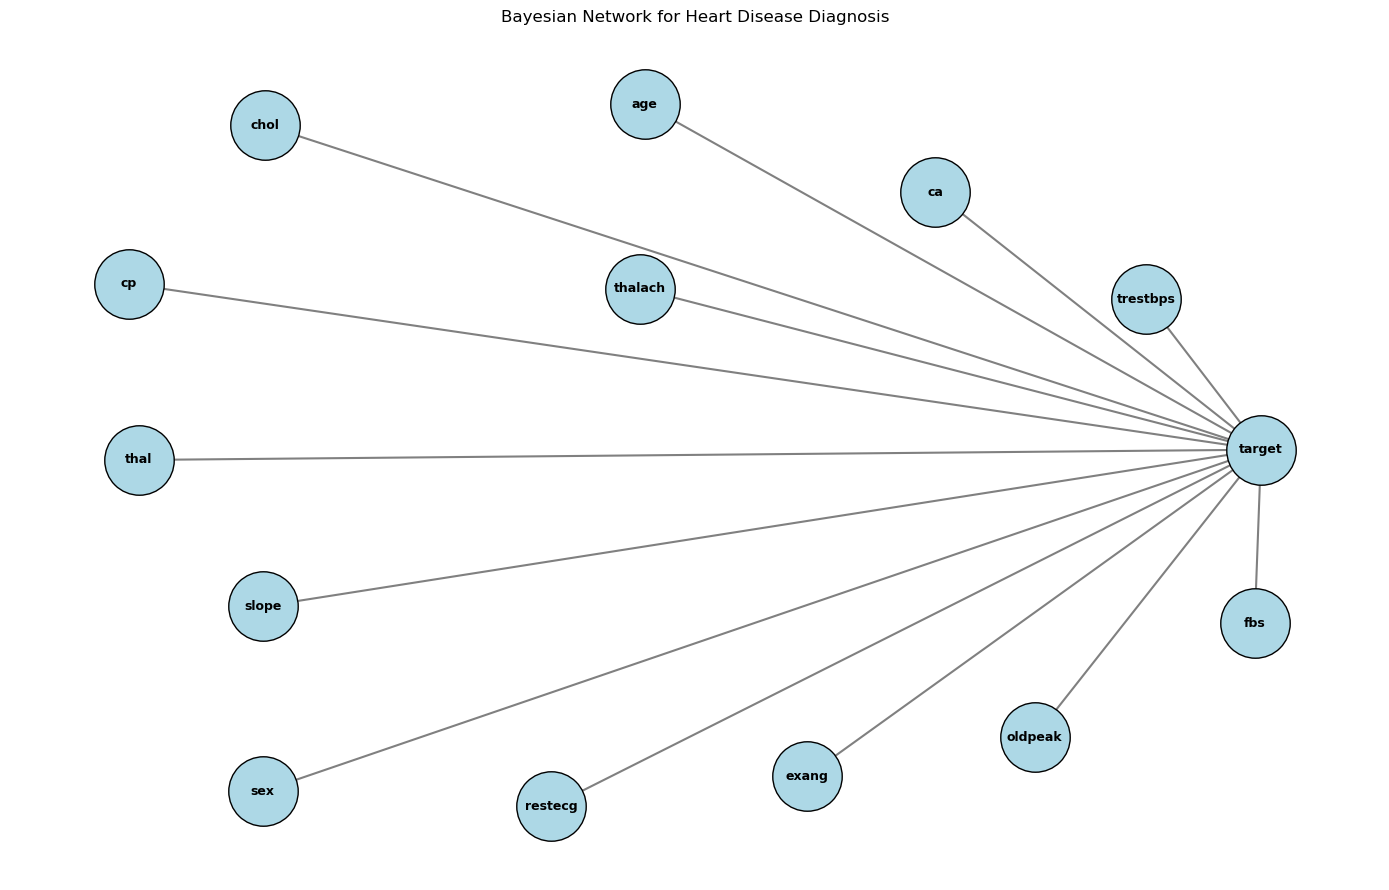

Bayesian Network visualization completed!


In [8]:
import matplotlib.pyplot as plt
import networkx as nx

# Create a directed graph
G = nx.DiGraph()

# Add nodes and edges from Bayesian Network
G.add_nodes_from(model.nodes())
G.add_edges_from(model.edges())

# Set figure size
plt.figure(figsize=(14, 9))

# Calculate node positions
pos = nx.spring_layout(G, seed=42, k=1.5)

# Draw nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2500,
    node_color="lightblue",
    edgecolors="black"
)

# Draw edges without arrows to avoid the Matplotlib error
nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    width=1.5,
    arrows=False
)

# Draw labels
nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
    font_weight="bold"
)

plt.title("Bayesian Network for Heart Disease Diagnosis")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Bayesian Network visualization completed!")

In [9]:
# Train Bayesian Network using the new pgmpy API

from pgmpy.parameter_estimator import DiscreteMLE

# Train the model using DiscreteMLE
model.fit(
    train_data,
    estimator=DiscreteMLE()
)

print("Bayesian Network trained successfully!")

# Display Conditional Probability Tables
print("\nLearned Conditional Probability Tables:")

for cpd in model.get_cpds():
    print(cpd)
    print("-----------------------------")

Bayesian Network trained successfully!

Learned Conditional Probability Tables:
+-------------+----------+
| age(high)   | 0.253165 |
+-------------+----------+
| age(low)    | 0.206751 |
+-------------+----------+
| age(medium) | 0.540084 |
+-------------+----------+
-----------------------------
+-----------+----------------+---------------+-----+-----------------+-----------------+------------------+
| age       | age(high)      | age(high)     | ... | age(medium)     | age(medium)     | age(medium)      |
+-----------+----------------+---------------+-----+-----------------+-----------------+------------------+
| ca        | ca(0.0)        | ca(0.0)       | ... | ca(3.0)         | ca(3.0)         | ca(3.0)          |
+-----------+----------------+---------------+-----+-----------------+-----------------+------------------+
| chol      | chol(high)     | chol(high)    | ... | chol(medium)    | chol(medium)    | chol(medium)     |
+-----------+----------------+---------------+-----+-

In [14]:
# Perform Heart Disease Diagnosis

from pgmpy.inference import VariableElimination

# Create inference object
inference = VariableElimination(model)

actual_values = []
predicted_values = []

print("Starting Heart Disease Diagnosis...")
print("------------------------------------")

# Test each patient
for index, row in test_data.iterrows():

    evidence = {
        column: str(row[column])
        for column in test_data.columns
        if column != "target"
    }

    # Calculate probability
    result = inference.query(
        variables=["target"],
        evidence=evidence,
        show_progress=False
    )

    # Find probability of heart disease (target = 1)
    states = list(result.state_names["target"])
    disease_index = states.index("1")

    probability = result.values[disease_index]

    prediction = 1 if probability >= 0.5 else 0

    actual_values.append(int(row["target"]))
    predicted_values.append(prediction)

print("\nDiagnosis completed successfully!")

print("Total patients tested:", len(test_data))
print("Total predictions:", len(predicted_values))

print("\nFirst 10 patient predictions:")

for i in range(min(10, len(predicted_values))):
    diagnosis = (
        "Heart Disease"
        if predicted_values[i] == 1
        else "No Heart Disease"
    )

    print(f"Patient {i+1}: {diagnosis}")

print("\nCell 11 executed successfully!")

Starting Heart Disease Diagnosis...
------------------------------------

Diagnosis completed successfully!
Total patients tested: 60
Total predictions: 60

First 10 patient predictions:
Patient 1: No Heart Disease
Patient 2: Heart Disease
Patient 3: Heart Disease
Patient 4: Heart Disease
Patient 5: Heart Disease
Patient 6: No Heart Disease
Patient 7: Heart Disease
Patient 8: Heart Disease
Patient 9: Heart Disease
Patient 10: Heart Disease

Cell 11 executed successfully!


In [11]:
accuracy = accuracy_score(actual_values, predicted_values)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        actual_values,
        predicted_values,
        labels=[0, 1],
        target_names=["No Heart Disease", "Heart Disease"],
        zero_division=0
    )
)

print("Confusion Matrix:")
cm = confusion_matrix(actual_values, predicted_values, labels=[0, 1])
print(cm)

Model Accuracy: 56.67 %

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       1.00      0.19      0.32        32
   Heart Disease       0.52      1.00      0.68        28

        accuracy                           0.57        60
       macro avg       0.76      0.59      0.50        60
    weighted avg       0.78      0.57      0.49        60

Confusion Matrix:
[[ 6 26]
 [ 0 28]]


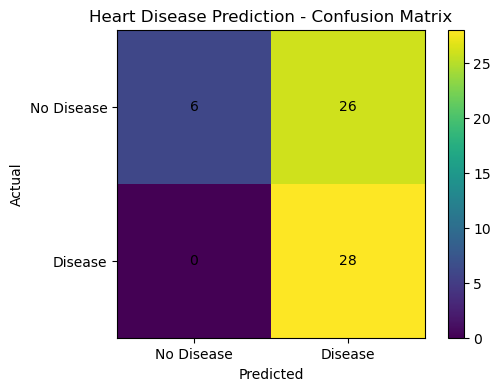

In [12]:
plt.figure(figsize=(6, 4))

plt.imshow(cm, interpolation="nearest")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [15]:
# Sample patient for heart disease diagnosis

sample_patient = {
    "age": "high",
    "sex": "1.0",
    "cp": "3.0",
    "trestbps": "high",
    "chol": "high",
    "fbs": "0.0",
    "restecg": "0.0",
    "thalach": "low",
    "exang": "1.0",
    "oldpeak": "high",
    "slope": "2.0",
    "ca": "2.0",
    "thal": "3.0"
}

# Perform Bayesian inference
sample_result = inference.query(
    variables=["target"],
    evidence=sample_patient,
    show_progress=False
)

# Extract probabilities
prob_no_disease = sample_result.values[0]
prob_disease = sample_result.values[1]

# Display diagnosis
print("HEART DISEASE DIAGNOSIS")
print("----------------------")

print(
    "Probability of No Heart Disease:",
    round(prob_no_disease * 100, 2), "%"
)

print(
    "Probability of Heart Disease:",
    round(prob_disease * 100, 2), "%"
)

if prob_disease >= 0.5:
    print("\nModel Prediction: Heart Disease")
else:
    print("\nModel Prediction: No Heart Disease")

HEART DISEASE DIAGNOSIS
----------------------
Probability of No Heart Disease: 50.0 %
Probability of Heart Disease: 50.0 %

Model Prediction: Heart Disease
